In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [ ]:
print(a['labels'])

[0 0 0 ... 1 1 1]


../debug_logits/task_0_eval.pkl
../debug_logits/task_1_eval.pkl
../debug_logits/task_2_eval.pkl


KeyError: 'logits'

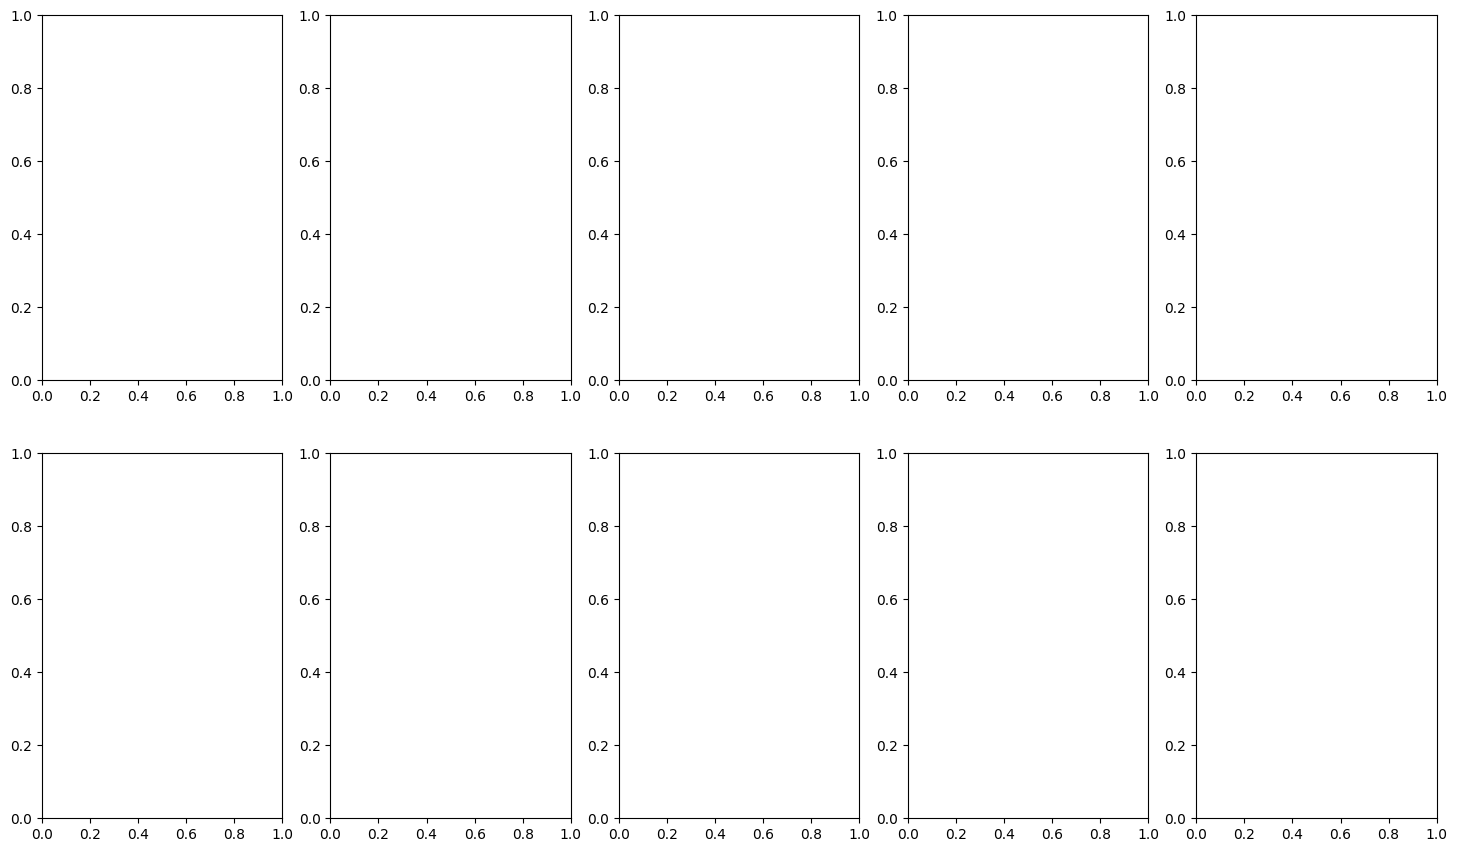

In [71]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
from matplotlib.lines import Line2D
# Usiamo tab10 o viridis per distinguere i batch
cmap = plt.get_cmap('tab10') 

fig, axs = plt.subplots(2, 5, figsize=(18, 11))
fig.subplots_adjust(bottom=0.15) # Crea spazio in fondo
for j in range(5):
    all_logits = []
    all_labels = []
    batch_indices = [] # Per tenere traccia di quale batch è quale
    
    filename = f'../debug_logits/task_{j}_eval.pkl'
    print(filename)
    try:
        with open(filename, 'rb') as f:
            batch_count = j
            while True:
                try: 
                    data = pickle.load(f)
                    logits_batch = data['logits']
                    labels_batch = data['labels']
                    print('labels_batch',labels_batch.shape)
                    all_logits.append(logits_batch)
                    all_labels.append(labels_batch)
                    
                    # Creiamo un array di indici che identifica questo batch
                    # Serve per colorare correttamente ogni riga dopo la concatenazione
                    batch_indices.append(np.full(labels_batch.shape[0], batch_count))
                    
                    batch_count += 1
                except EOFError:
                    break
    except FileNotFoundError:
        continue

    if not all_logits: continue

    # Concateniamo tutto per gestire le maschere delle classi
    lab = np.concatenate(all_labels[:-1])
    logits = np.concatenate(all_logits[:-1])
    indices = np.concatenate(batch_indices[:-1])
    print(np.unique(indices))
    unique_labels = np.unique(lab)

    for i, v in enumerate(unique_labels):
        if i >= 2: break # Sicurezza per il subplot 2x5
        
        ax = axs[i][j]
        ax.set_title(f'Eval Task {j} | Class {v}')
        
        mask = (lab == v)
        # Filtriamo logits e indici del batch per la classe corrente
        selected_logits = logits[mask]
        selected_indices = indices[mask]
        
        # Plottiamo ogni batch separatamente per applicare il colore corretto
        for b_idx in np.unique(selected_indices):
            batch_mask = (selected_indices == b_idx)
            color = cmap(int(b_idx) % 10) # Cicla sui colori se i batch sono > 10
            
            # plot dei campioni di questo batch per questa classe
            # .T perché vogliamo i neuroni (output) sull'asse X
            ax.plot(selected_logits[batch_mask].T, 'x', color=color, alpha=0.4)

        ax.set_xlabel('Output neuron index')
        ax.set_ylabel('Logit value')
        ax.grid(True, alpha=0.3)

# --- CREAZIONE LEGENDA GLOBALE ---
# Creiamo dei proxy artists (linee invisibili con il colore corretto)
legend_elements = [
    Line2D([0], [0], marker='x', color='w', label=f'Eval {m}',
           markerfacecolor=cmap(m % 10), markeredgecolor=cmap(m % 10), markersize=10)
    for m in range(5)
]

# Posizioniamo la legenda in fondo al centro
fig.legend(handles=legend_elements, 
           loc='lower center', 
           ncol=5, # Mette le etichette su una riga
           bbox_to_anchor=(0.5, 0.02), # Coordinate (x, y) relative alla figura
           title="Fasi di Valutazione (Batch salvati nel tempo)",
           frameon=True,
           fontsize=12)

plt.show()

In [72]:
for j in range(5):
    all_logits = []
    all_labels = []
    batch_indices = [] # Per tenere traccia di quale batch è quale
    
    filename = f'../debug_logits_last/task_{j}_eval.pkl'
    print(filename)
    try:
        with open(filename, 'rb') as f:
            batch_count = j
            while True:
                try: 
                    data = pickle.load(f)
                    logits_batch = data['logits']
                    labels_batch = data['labels']
                    print('labels_batch',labels_batch.shape)
                    all_logits.append(logits_batch)
                    all_labels.append(labels_batch)
                    
                    # Creiamo un array di indici che identifica questo batch
                    # Serve per colorare correttamente ogni riga dopo la concatenazione
                    batch_indices.append(np.full(labels_batch.shape[0], batch_count))
                    
                    batch_count += 1
                    
                except EOFError:
                    break
    except FileNotFoundError:
        continue
    
    lab = np.concatenate(all_labels[:-1])
    logits = np.concatenate(all_logits[:-1])
    indices = np.concatenate(batch_indices[:-1])
    print(np.unique(indices))
    for j in np.unique(indices):
        mask_id=(indices==j)
        lab_id=lab[mask_id]
        unique_labels = np.unique(lab_id)
            
        for i, v in enumerate(unique_labels):
            
            mask = (lab_id == v)
            # Filtriamo logits e indici del batch per la classe corrente
            selected_logits = logits[mask_id][mask]
            for i in range(5):
                print(f'during evaluation of batch {j} logits for label {v} are {np.round(selected_logits[i],3)}')

../debug_logits_last/task_0_eval.pkl
labels_batch (1000,)
labels_batch (1000,)
labels_batch (1000,)
labels_batch (1000,)
labels_batch (1000,)
labels_batch (2000,)
[0 1 2 3 4]
during evaluation of batch 0 logits for label 0 are [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 0 are [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 0 are [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 0 are [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 0 are [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 1 are [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 1 are [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 1 are [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 1 are [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
during evaluation of batch 0 logits for label 1 are [0. 1. 0. 0. 0. 0

(10,)
(10,)


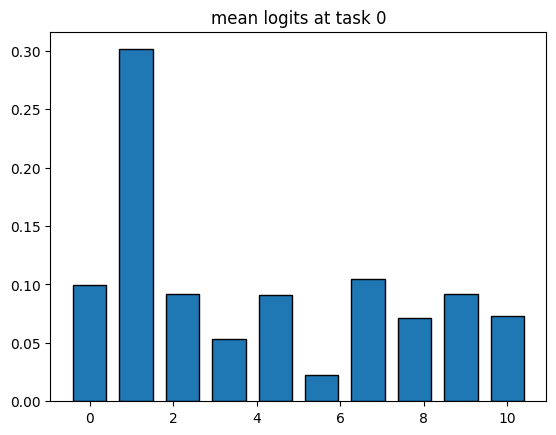

(5000, 10)
(10,)


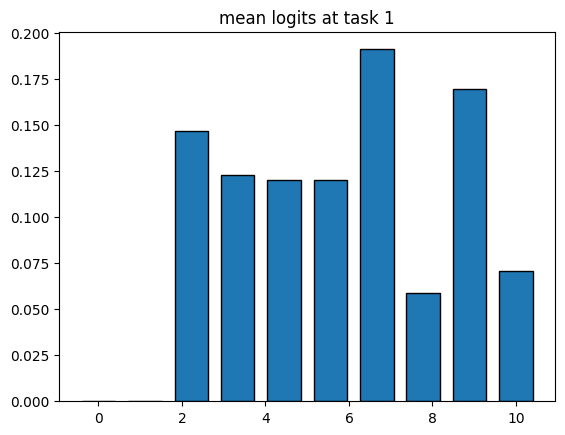

(4000, 10)
(10,)


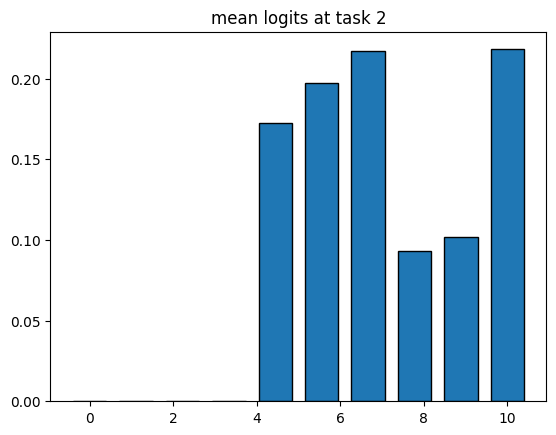

(3000, 10)
(10,)


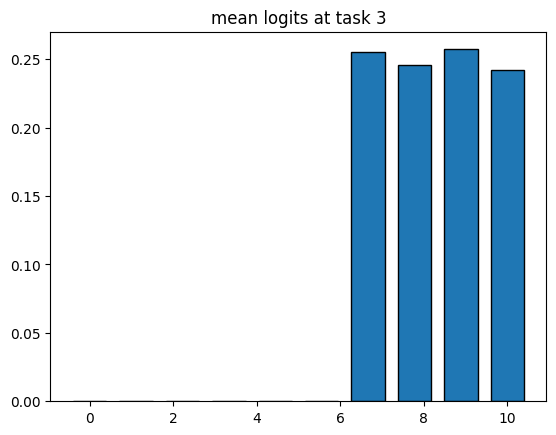

(2000, 10)
(10,)


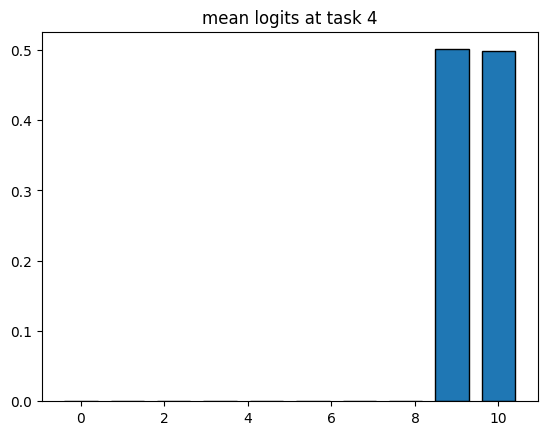

(1000, 10)


In [40]:
import matplotlib.pyplot as plt
import numpy as np
import pickle
from matplotlib.lines import Line2D
# Usiamo tab10 o viridis per distinguere i batch

for j in range(5):
    all_logits = []
    all_labels = []
    batch_indices = [] # Per tenere traccia di quale batch è quale
    
    filename = f'../debug_logits_last/task_{j}_eval.pkl'
    # print(filename)
    try:
        with open(filename, 'rb') as f:
            batch_count = j
            while True:
                try: 
                    data = pickle.load(f)
                    logits_batch = data['logits']
                    labels_batch = data['labels']
                    # print('labels_batch',labels_batch.shape)
                    all_logits.append(logits_batch)
                    all_labels.append(labels_batch)
                    
                    # Creiamo un array di indici che identifica questo batch
                    # Serve per colorare correttamente ogni riga dopo la concatenazione
                    batch_indices.append(np.full(labels_batch.shape[0], batch_count))
                    
                    batch_count += 1
                except EOFError:
                    break
    except FileNotFoundError:
        continue

    if not all_logits: continue 
    if not j:
        logits=np.concatenate(all_logits[:-1])
        logits_sum = np.sum(logits,axis=0)
        print(logits_sum.shape)
        n_logits=logits.shape[0]
        l_mean=logits_sum/n_logits
        print(l_mean.shape)
    else:
        logits=np.concatenate(all_logits[:-1])
        logits_sum = np.sum(logits,axis=0)
        # logits_sum += np.sum(logits,axis=0)
        # n_logits+=logits.shape[0]
        n_logits=logits.shape[0]
        l_mean=logits_sum/n_logits
        print(l_mean.shape)
    plt.figure()
    plt.title(f'mean logits at task {j}')
    plt.bar(np.linspace(0,10,10),l_mean,width=0.8,edgecolor='k')
    plt.show()
    
    print(logits.shape)

# print(logits)
# plt.bar(np.linspace(0,10,10),logits,width=0.8,edgecolor='k')

In [15]:
import torch
checkpoint = torch.load("../checkpoints/resnet18_scifar10_sgd_joint_inference.pt")
checkpoint['optimizer']['param_groups']
if isinstance(checkpoint, dict) and 'model' in checkpoint:
    # Caso standard di Mammoth: i pesi sono dentro la chiave 'model'
    weights_only = checkpoint['model']
    print("Trovata chiave 'model'. Estrazione dei pesi completata.")
new_ckpt_path = "../checkpoints/resnet18_scifar10_weights_only.pt"
torch.save(weights_only, new_ckpt_path)
print(f"Nuovo checkpoint con SOLI pesi salvato in: {new_ckpt_path}")

Trovata chiave 'model'. Estrazione dei pesi completata.
Nuovo checkpoint con SOLI pesi salvato in: ../checkpoints/resnet18_scifar10_weights_only.pt


/tmp/ipykernel_1950/2126533476.py:41: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_c.show()
/tmp/ipykernel_1950/2126533476.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_t.show()


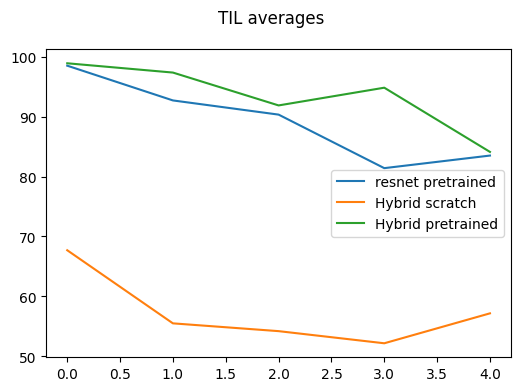

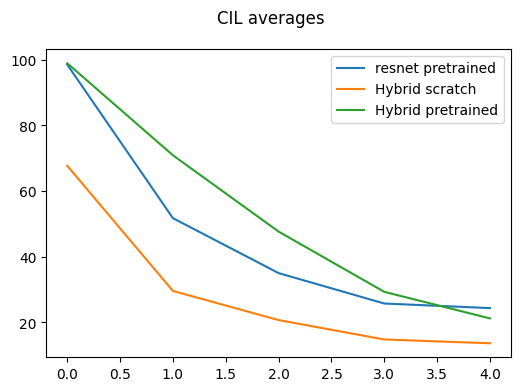

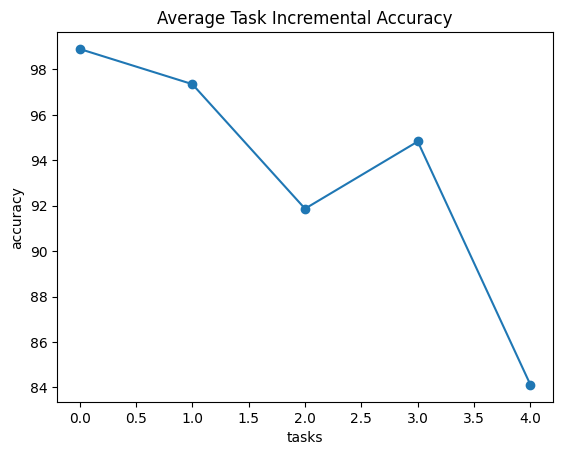

Text(0, 0.5, 'accuracy')

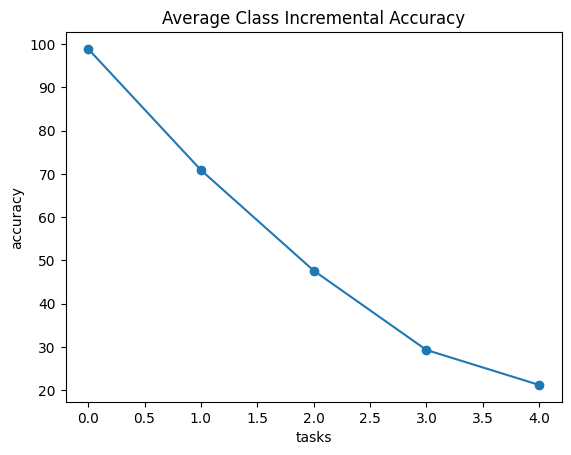

In [9]:


import numpy as np
import matplotlib.pyplot as plt

fig_t, ax_t = plt.subplots(figsize=(6, 4))
fig_t.suptitle("TIL averages")

fig_c, ax_c = plt.subplots(figsize=(6, 4))
fig_c.suptitle("CIL averages")

# RESNET pretrained
CIL=[[98.5], [7.9, 95.6],[2.6, 7.2, 95.3],[0.0, 2.5, 3.4, 97.2] ,[0.5, 0.0, 3.4, 19.2, 98.8]]
CIL_avgs=[np.mean(l) for l in CIL]
ax_c.plot(CIL_avgs,label='resnet pretrained')
TIL=[[98.5],[89.8, 95.6],[83.8, 91.9, 95.3],[60.6, 83.6, 84.2, 97.2],
[57.1, 80.3, 84.0, 97.3, 98.8]]
TIL_avgs=[np.mean(l) for l in TIL]
ax_t.plot(TIL_avgs,label='resnet pretrained')


# Hybrid scratch
CIL=[[67.7], [0.0, 59.2],[0.0, 0.0, 62.2],[0.0, 0.0, 0.0, 59.3] ,[0.0, 0.0, 0.0, 0.0, 68.35]]
CIL_avgs=[np.mean(l) for l in CIL]
ax_c.plot(CIL_avgs,label='Hybrid scratch')


TIL=[[67.7],[51.8, 59.2],[50.4, 50.0, 62.2],[48.6, 50.8, 50.0, 59.3],[55.25, 50.05, 62.1, 50.05, 68.4]]
TIL_avgs=[np.mean(l) for l in TIL]
ax_t.plot(TIL_avgs,label='Hybrid scratch')

# Hybrid pretrained
CIL=[[98.9], [45.7, 96.1],[43.0, 3.1, 96.89999999999999],[11.6, 0.0, 6.6, 99.1] ,[0.1, 3.35, 4.0, 0.2, 98.55]]
CIL_avgs=[np.mean(l) for l in CIL]
ax_c.plot(CIL_avgs,label='Hybrid pretrained')

TIL=[[98.9],[98.6, 96.1],[93.60000000000001, 85.1, 96.89999999999999],[98.1, 86.8, 95.3, 99.1],[95.65, 50.0, 79.2, 97.15, 98.55000000000001]]
TIL_avgs=[np.mean(l) for l in TIL]
ax_t.plot(TIL_avgs,label='Hybrid pretrained')

ax_t.legend()
ax_c.legend()
fig_c.show()
fig_t.show()

plt.figure()
plt.title('Average Task Incremental Accuracy')
plt.plot(TIL_avgs,'-o')
plt.xlabel('tasks')
plt.ylabel('accuracy')
plt.show()
plt.title('Average Class Incremental Accuracy')
plt.plot(CIL_avgs,'-o')
plt.xlabel('tasks')
plt.ylabel('accuracy')

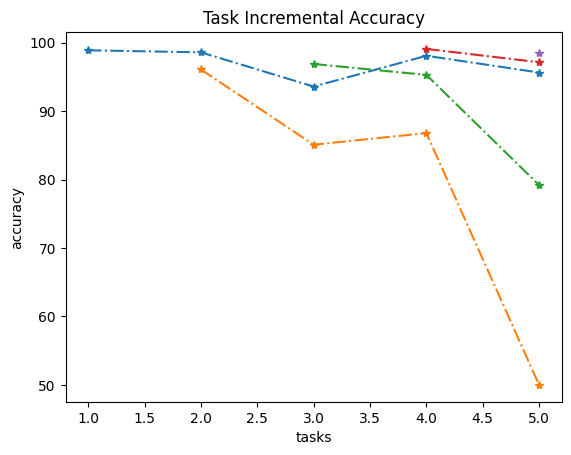

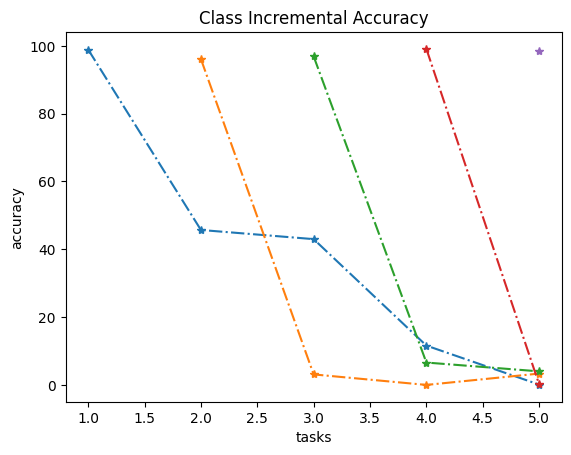

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
cmap=plt.get_cmap('tab10')
c=[cmap(i) for i in np.linspace(0,1,5)]
plt.figure()
plt.title('Task Incremental Accuracy')
plt.xlabel('tasks')
plt.ylabel('accuracy')
for i in range(5):
    k=[l[i] for l in TIL[i:]]
    plt.plot(np.arange(i+1,5+1),k,'*-.')
    
plt.figure()
plt.title('Class Incremental Accuracy')
plt.xlabel('tasks')
plt.ylabel('accuracy')
for i in range(5):
    k=[l[i] for l in CIL[i:]]
    plt.plot(np.arange(i+1,5+1),k,'*-.')

In [12]:
save_path='../debug_logits'
num_tasks=5
for k in range(0, num_tasks):
    for i in range(0,k+1):
        filename = f"{save_path}/task_{(k+1)*2}_{i}_eval.pkl"
        print(filename)

../debug_logits/task_2_0_eval.pkl
../debug_logits/task_4_0_eval.pkl
../debug_logits/task_4_1_eval.pkl
../debug_logits/task_6_0_eval.pkl
../debug_logits/task_6_1_eval.pkl
../debug_logits/task_6_2_eval.pkl
../debug_logits/task_8_0_eval.pkl
../debug_logits/task_8_1_eval.pkl
../debug_logits/task_8_2_eval.pkl
../debug_logits/task_8_3_eval.pkl
../debug_logits/task_10_0_eval.pkl
../debug_logits/task_10_1_eval.pkl
../debug_logits/task_10_2_eval.pkl
../debug_logits/task_10_3_eval.pkl
../debug_logits/task_10_4_eval.pkl


In [ ]:
import pickle
    
filename='../debug_logits/task_10_4_eval.pkl'
with open(filename, 'rb') as f:
    data = pickle.load(f)
    print(data.keys())
    print(data['accs'])
    print(data['accs_mask_classes'])

filename='../debug_logits/task_10_3_eval.pkl'
with open(filename, 'rb') as f:
    data = pickle.load(f)
    print(data.keys())
    print(data['accs'])
    print(data['accs_mask_classes'])

dict_keys(['logits', 'labels', 'accs', 'accs_mask_classes'])
[85.9, 84.8, 38.5, 83.3, 48.0]
[97.1, 87.3, 42.3, 94.6, 52.1]
dict_keys(['logits', 'labels', 'accs', 'accs_mask_classes'])
[85.9, 84.8, 38.5, 83.3]
[97.1, 87.3, 42.3, 94.6]
(1000, 10)


In [21]:
for k in range(0,2):
    filename=f'../debug_logits/task_4_{k}_eval.pkl'
    with open(filename, 'rb') as f:
        data = pickle.load(f)
        print(data['accs'])

[85.7]
[85.7, 95.6]


In [80]:
import os
import pickle
import glob
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

def analyze_logits_across_tasks(save_path, num_tasks=5):
    """
    Legge i file .pkl generati durante l'evaluation e plotta la media dei logit 
    prodotti dalla rete per ciascun task.
    """

    cil_accs = []
    til_accs = []
    for k in range(0, num_tasks):
        task_logit_means = []
        for i in range(0,k+1):
            filename = f"{save_path}/task_{(k+1)*2}_eval_{i}_logits.pkl"
            print(filename)
            if not os.path.exists(filename):
                print(f"File non trovato: {filename}")
                continue

            all_logits = []
            
            # Gestisce i pickle salvati in modalità 'ab' (append)
            with open(filename, 'rb') as f:
                while True:
                    try:
                        data = pickle.load(f)
                        all_logits.append(data['logits'])
                    except EOFError:
                        break  # Fine del file
            # print(f'logits {k} {i} : ',data['logits'])
            # Concateniamo tutti gli array di logit accumulati nel file
                    # Shape finale: [N_campioni, N_classi_totali]
                    concat_logits = np.concatenate(all_logits, axis=0)
                    # print(all_logits.shape)
                    # print(concat_logits.shape)
                    # Calcoliamo la media dei logit lungo la dimensione dei campioni (dim=0)
                    # Risultato: un array 1D con il logit medio per ogni classe [mean_c0, mean_c1, ...]
                    mean_logits = np.mean(concat_logits, axis=0)
                    task_logit_means.append(mean_logits)
            
        filename = f"{save_path}/task_{(k+1)*2}_eval.pkl"
        print(filename)
        if not os.path.exists(filename):
            print(f"File non trovato: {filename}")
            continue

        
        # Gestisce i pickle salvati in modalità 'ab' (append)
        with open(filename, 'rb') as f:
            while True:
                try:
                    data = pickle.load(f)
                    print(k,data[f'accs'])
                    cil_accs.append(data[f'accs'])
                    til_accs.append(data[f'accs_mask_classes'])
                except EOFError:
                    break  # Fine del file
        # print(f'logits {k} {i} : ',data['logits'])
        


        
        # print(f"Task {k} - Logit medi per classe: {np.round(mean_logits, 3)}")
        print(f"Task {k} - accs: {cil_accs}")
        print(f"Task {k} - accs_mask: {til_accs}")

    # --- PLOTTING ---
    plt.figure(figsize=(10, 6))
    
    num_classes = len(task_logit_means[0]) if task_logit_means else 0
    epochs_eval = range(1, len(task_logit_means) + 1)

    # Convertiamo in matrice 2D per comodità: [Task_eval, Classi]
    task_logit_means = np.array(task_logit_means)

    for c in range(num_classes):
        # Tracciamo l'evoluzione della classe 'c' al trascorrere dei task
        plt.plot(epochs_eval, task_logit_means[:, c], marker='o', linewidth=2, label=f'Classe {c}')

    plt.title('Evoluzione della Media dei Logit per Classe al progredire dei Task')
    plt.xlabel('Task Valutato / Completato')
    plt.ylabel('Valore Medio del Logit')
    plt.xticks(epochs_eval)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(f"{save_path}/logits_evolution.png", bbox_inches='tight')

    cmap=plt.get_cmap('tab10')
    c=[cmap(i) for i in np.linspace(0,1,5)]
    plt.figure()
    plt.title('Task Incremental Accuracy')
    plt.xlabel('tasks')
    plt.ylabel('accuracy')
    for i in range(5):
        k=[l[i] for l in til_accs[i:]]
        print(i,k)

        plt.plot(np.arange(i+1,5+1),k,'*-.')
    plt.savefig(f"{save_path}/til_accs.png", bbox_inches='tight')
        
    plt.figure()
    plt.title('Class Incremental Accuracy')
    plt.xlabel('tasks')
    plt.ylabel('accuracy')
    for i in range(5):
        k=[l[i] for l in cil_accs[i:]]
        plt.plot(np.arange(i+1,5+1),k,'*-.')
    plt.savefig(f"{save_path}/cil_accs.png", bbox_inches='tight')
    # --- ESECUZIONE ---
# Inserisci il tuo save_path qui
analyze_logits_across_tasks('../debug_logits', num_tasks=5)

../debug_logits/task_2_eval_0_logits.pkl
../debug_logits/task_2_eval.pkl
0 [99.25]
Task 0 - accs: [[99.25]]
Task 0 - accs_mask: [[99.25]]
../debug_logits/task_4_eval_0_logits.pkl
../debug_logits/task_4_eval_1_logits.pkl
../debug_logits/task_4_eval.pkl
1 [97.0, 93.25]
Task 1 - accs: [[99.25], [97.0, 93.25]]
Task 1 - accs_mask: [[99.25], [98.85000000000001, 95.0]]
../debug_logits/task_6_eval_0_logits.pkl
../debug_logits/task_6_eval_1_logits.pkl
../debug_logits/task_6_eval_2_logits.pkl
../debug_logits/task_6_eval.pkl
2 [97.85000000000001, 85.39999999999999, 89.8]
Task 2 - accs: [[99.25], [97.0, 93.25], [97.85000000000001, 85.39999999999999, 89.8]]
Task 2 - accs_mask: [[99.25], [98.85000000000001, 95.0], [99.1, 93.2, 91.64999999999999]]
../debug_logits/task_8_eval_0_logits.pkl
../debug_logits/task_8_eval_1_logits.pkl
../debug_logits/task_8_eval_2_logits.pkl
../debug_logits/task_8_eval_3_logits.pkl
../debug_logits/task_8_eval.pkl
3 [97.75, 80.10000000000001, 86.8, 47.349999999999994]
Task 3

In [15]:
import numpy as np
data=np.load('../data/cifar10_feats/test_feats.npz')
dir(data)

print(type(data['labels']))

<class 'numpy.ndarray'>


## OMY Experiments

/tmp/ipykernel_1268265/3007981851.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_c.show()
/tmp/ipykernel_1268265/3007981851.py:64: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig_t.show()


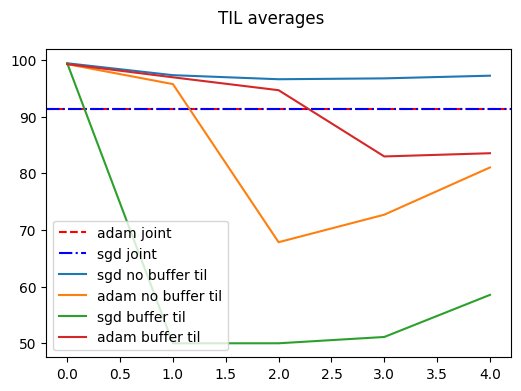

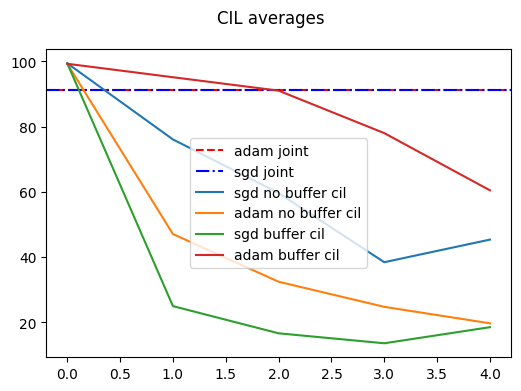

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

joint_acc_adam=91.35
joint_acc_sgd=91.29

# RESNET pretrained No buffer

no_buff_sgd_cil=[[99.4] ,[57.0, 95.15],[53.75, 27.7, 97.5],[35.25, 5.1, 14.1, 99.35],[20.3, 0.2, 27.0, 80.55, 98.85]  ]
no_buff_sgd_til=[[99.4] ,[99.45, 95.15],[96.8, 95.45, 97.5],[96.95, 95.5, 95.1, 99.4], [97.1, 95.4, 95.25, 99.4, 98.9]]


no_buff_adam_cil=[[99.25],[0.0, 94.15] ,[0.0, 0.0, 97.4] , [0.0, 0.0, 0.0, 99.1] ,[0.0, 0.0, 0.0, 0.0, 98.65]  ]
no_buff_adam_til=[[99.25] ,[97.3, 94.15],[56.1, 50.0, 97.4],[50.0, 75.2, 66.45, 99.1], [50.85, 64.25, 92.45, 98.9, 98.65]]

# RESNET pretrained buffer 1000
buff_sgd_cil=[[99.4] , [0.0, 50.0],[0.0, 0.0, 50.0],[0.0, 0.0, 0.0, 54.45],[0.0, 0.0, 0.0, 0.0, 92.7]   ]
buff_sgd_til=[[99.4] ,[50.0, 50.0],[50.0, 50.0, 50.0],[50.0, 50.0, 50.0, 54.45],[50.0, 50.0, 50.0, 50.0, 92.7]]

buff_adam_cil=[[99.25] ,[97.0, 93.25] ,[97.85, 85.4, 89.8],[97.75, 80.1, 86.8, 47.35],[93.2, 87.7, 78.75, 42.7, 0.0]   ]
buff_adam_til=[[99.25], [98.85, 95.0], [99.1, 93.2, 91.65],[98.85, 90.15, 89.95, 52.9],[96.95, 91.35, 83.85, 94.2, 51.3]]

fig_t, ax_t = plt.subplots(figsize=(6, 4))
fig_t.suptitle("TIL averages")

fig_c, ax_c = plt.subplots(figsize=(6, 4))
fig_c.suptitle("CIL averages")

ax_c.axhline(y=joint_acc_adam, color='r', linestyle='--', label='adam joint')
ax_c.axhline(y=joint_acc_sgd, color='b', linestyle='-.', label='sgd joint')
ax_t.axhline(y=joint_acc_adam, color='r', linestyle='--', label='adam joint')
ax_t.axhline(y=joint_acc_sgd, color='b', linestyle='-.', label='sgd joint')

# RESNET pretrained
CIL_avgs=[np.mean(l) for l in no_buff_sgd_cil]
ax_c.plot(CIL_avgs,label='sgd no buffer cil')
TIL_avgs=[np.mean(l) for l in no_buff_sgd_til]
ax_t.plot(TIL_avgs,label='sgd no buffer til')


# Hybrid scratch
CIL_avgs=[np.mean(l) for l in no_buff_adam_cil]
ax_c.plot(CIL_avgs,label='adam no buffer cil')

TIL_avgs=[np.mean(l) for l in no_buff_adam_til]
ax_t.plot(TIL_avgs,label='adam no buffer til')

# Hybrid pretrained
CIL_avgs=[np.mean(l) for l in buff_sgd_cil]
ax_c.plot(CIL_avgs,label='sgd buffer cil')

TIL_avgs=[np.mean(l) for l in buff_sgd_til]
ax_t.plot(TIL_avgs,label='sgd buffer til')

CIL_avgs=[np.mean(l) for l in buff_adam_cil]
ax_c.plot(CIL_avgs,label='adam buffer cil')

TIL_avgs=[np.mean(l) for l in buff_adam_til]
ax_t.plot(TIL_avgs,label='adam buffer til')

ax_t.legend()
ax_c.legend()
fig_c.show()
fig_t.show()


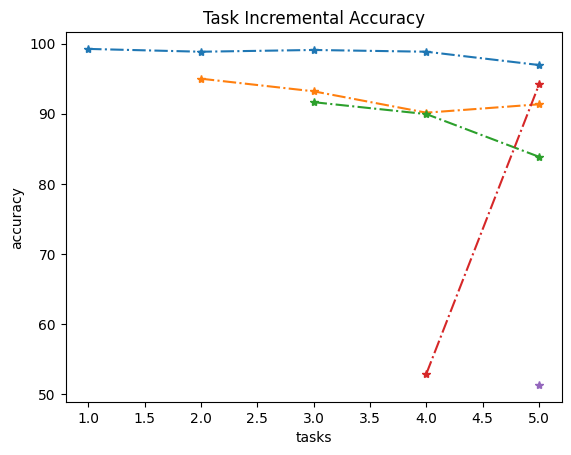

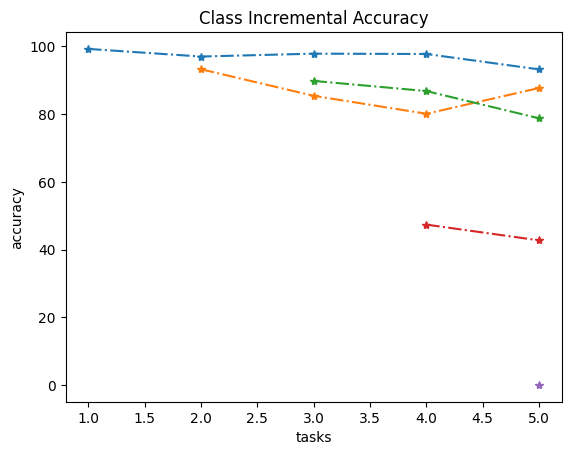

In [22]:

cmap=plt.get_cmap('tab10')
c=[cmap(i) for i in np.linspace(0,1,5)]
plt.figure()
plt.title('Task Incremental Accuracy')
plt.xlabel('tasks')
plt.ylabel('accuracy')
for i in range(5):
    k=[l[i] for l in buff_adam_til[i:]]
    plt.plot(np.arange(i+1,5+1),k,'*-.')
    
plt.figure()
plt.title('Class Incremental Accuracy')
plt.xlabel('tasks')
plt.ylabel('accuracy')
for i in range(5):
    k=[l[i] for l in buff_adam_cil[i:]]
    plt.plot(np.arange(i+1,5+1),k,'*-.')

In [40]:

filename = f'../debug_data_adam_buff1000/stats_task_1.pt'
print(filename)
data = torch.load(filename)

../debug_data_adam_buff1000/stats_task_1.pt


In [43]:
data['losses']

[{'main_grad': {'g_in': tensor([[-4.3727e-01, -4.3643e-01, -3.9247e-02,  ..., -7.3271e-02,
            -1.9495e-01, -4.7165e-03],
           [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  ...,  0.0000e+00,
             0.0000e+00,  0.0000e+00],
           [-4.3792e-01, -4.2179e-01, -2.1350e-02,  ..., -7.6239e-02,
            -1.9780e-01, -4.8369e-03],
           ...,
           [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  ...,  0.0000e+00,
             0.0000e+00,  0.0000e+00],
           [-3.4180e-01, -3.2057e-01,  1.7579e-03,  ..., -5.6826e-02,
            -1.5223e-01,  4.8314e-05],
           [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  ...,  0.0000e+00,
             0.0000e+00,  0.0000e+00]]),
   'g_rec': tensor([[-1.6927,  0.0000, -1.3584,  ...,  0.0000, -1.5573,  0.0000],
           [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
           [-1.7127,  0.0000, -1.3706,  ...,  0.0000, -1.5711,  0.0000],
           ...,
           [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000, 

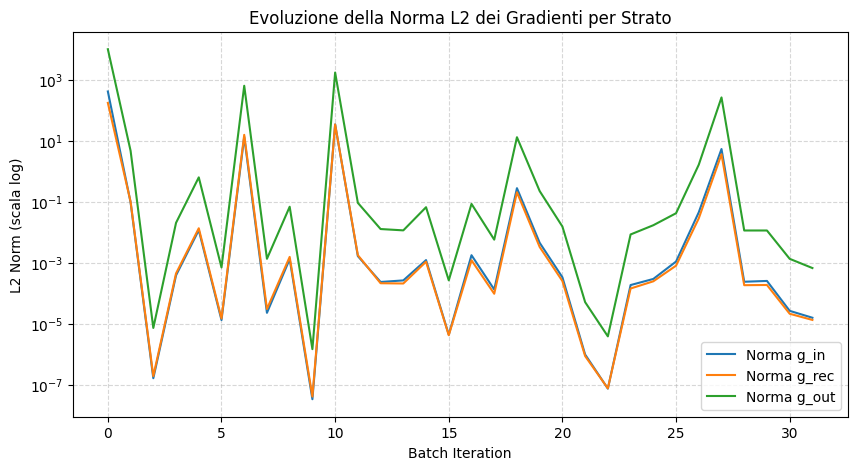

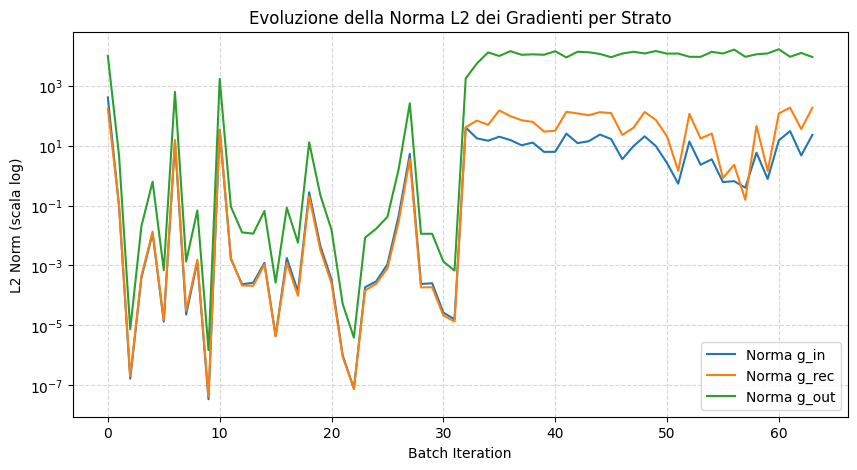

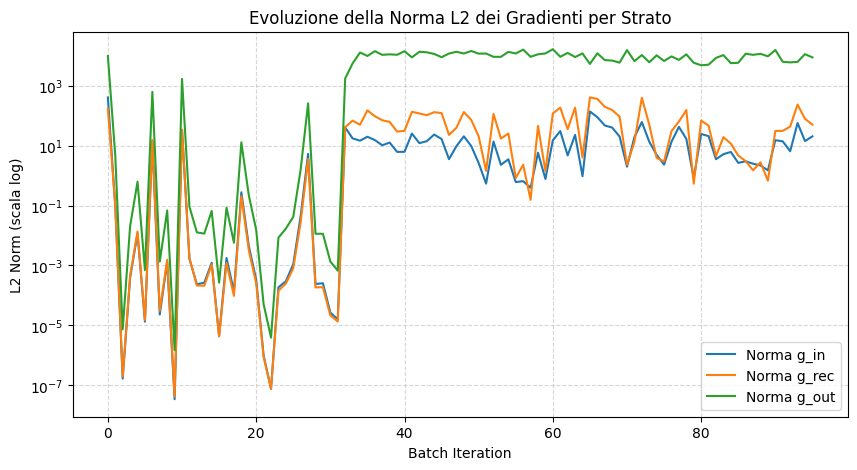

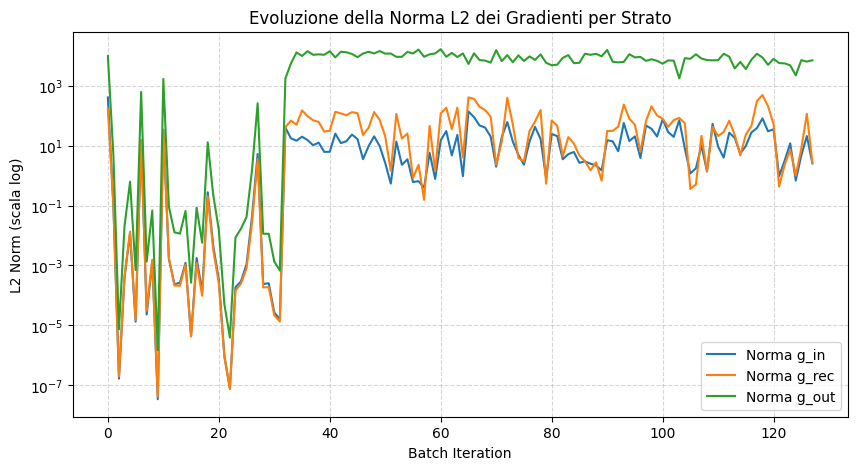

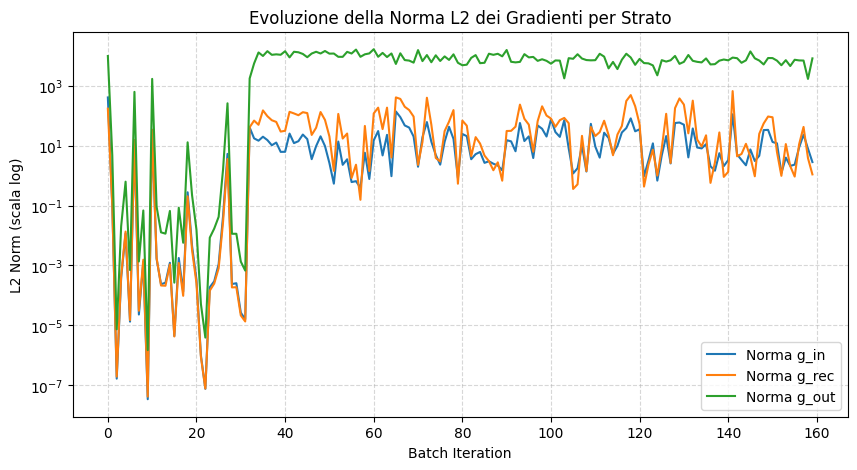

In [48]:

# Liste per salvare le norme dei gradienti per ogni strato
grad_norms = {
    'g_in': [],
    'g_rec': [],
    'g_out': []
}


# Dentro il tuo training loop:
for i in range(5):
    filename = f'../debug_data_nologits/stats_task_{i}.pt'
    data = torch.load(filename)
    for d in data['grads']:
        for key in grad_norms.keys():
            g_tensor = d['main_grad'][key]
            grad_norms[key].append(torch.norm(g_tensor, p=2).item())
    
    # --- PLOT DELLE NORME DEI GRADIENTI ---
    plt.figure(figsize=(10, 5))
    for key, values in grad_norms.items():
        plt.plot(values, label=f'Norma {key}')

    plt.yscale('log')  # Scala logaritmica fondamentale per vedere variazioni di ordini di grandezza!
    plt.title("Evoluzione della Norma L2 dei Gradienti per Strato")
    plt.xlabel("Batch Iteration")
    plt.ylabel("L2 Norm (scala log)")
    plt.grid(True, which="both", linestyle="--", alpha=0.5)
    plt.legend()
    plt.show()

shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])
shape of errors torch.Size([10, 16, 10])
shape of errors mean torch.Size([])


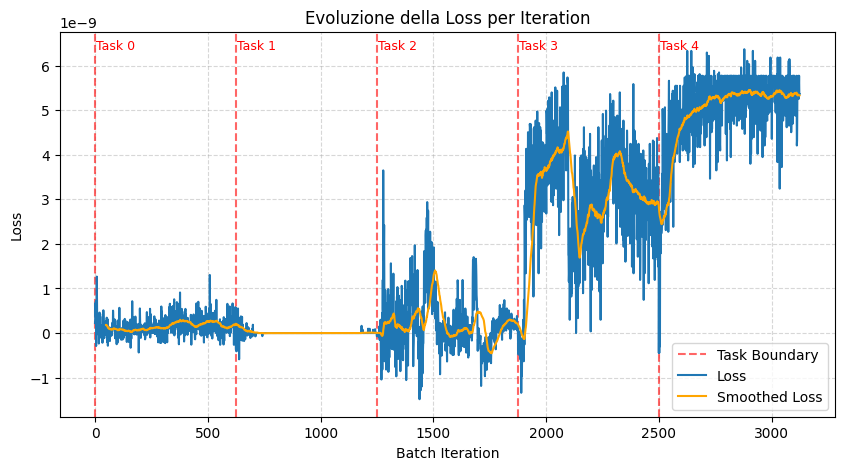

In [ ]:
losses=[]
task_boundaries = []
# Dentro il tuo training loop:
for i in range(5):
    filename = f'../debug_data_test/stats_task_{i}.pt'
    data = torch.load(filename)
    task_boundaries.append(len(losses))
    print('shape of errors',data['errors'][0].shape) # lr_win, batch_size, num_classes
    print('shape of errors mean',data['errors'][0].mean().shape)
    for d in data['errors']:
        losses.append(d.mean().item())
    
# --- PLOT DELLE NORME DEI GRADIENTI ---
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)
for task_idx, boundary in enumerate(task_boundaries):
    plt.axvline(
        x=boundary,
        color="red",
        linestyle="--",
        alpha=0.6,
        label="Task Boundary" if task_idx == 0 else "",
    )
    plt.text(
        boundary + 5,
        max(losses),
        f"Task {task_idx}",
        color="red",
        fontsize=9,
    )
plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()


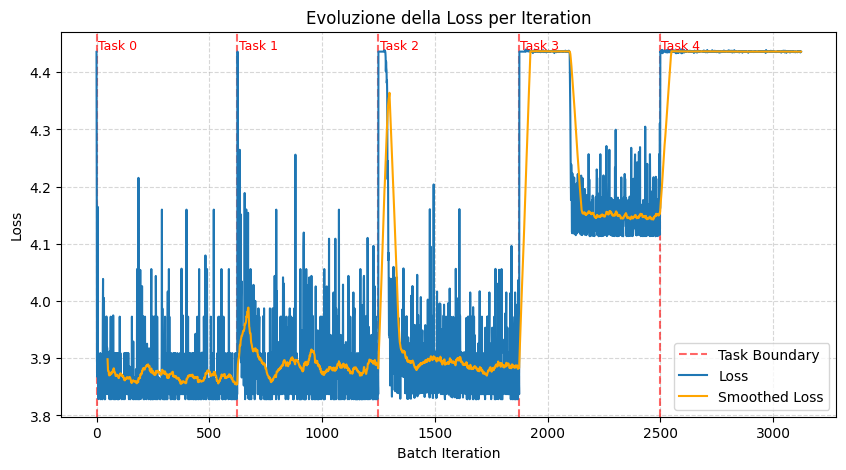

In [ ]:
losses=[]
task_boundaries = []
# Dentro il tuo training loop:
for i in range(5):
    filename = f'../debug_data_test/stats_task_{i}.pt'
    data = torch.load(filename)
    task_boundaries.append(len(losses))
    for d in data['losses']:
        losses.append(d)
    
# --- PLOT DELLE NORME DEI GRADIENTI ---
plt.figure(figsize=(10, 5))
# Aggiungiamo linee verticali per evidenziare il cambio di Task (Continual Learning)
for task_idx, boundary in enumerate(task_boundaries):
    plt.axvline(
        x=boundary,
        color="red",
        linestyle="--",
        alpha=0.6,
        label="Task Boundary" if task_idx == 0 else "",
    )
    plt.text(
        boundary + 5,
        max(losses),
        f"Task {task_idx}",
        color="red",
        fontsize=9,
    )
plt.plot(losses, label='Loss')
# plt.yscale('log')
plt.title("Evoluzione della Loss per Iteration")
plt.xlabel("Batch Iteration")
plt.ylabel("Loss")

#sliding window smoothing
window_size = 50
smoothed_losses = np.convolve(losses, np.ones(window_size)/window_size, mode='valid')
plt.plot(range(window_size-1, len(losses)), smoothed_losses, label='Smoothed Loss', color='orange')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()
